Libraries imported successfully!
Initial Dataset Shape: (1303, 13)


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60


Dropped 28 duplicate rows. New shape: (1275, 12)
Missing values per column:
 Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price_euros         0
dtype: int64
Outlier treatment completed via IQR winsorization.
Feature engineering complete. Retained features: ['Company', 'TypeName', 'Inches', 'Ram', 'OpSys', 'Weight', 'Price', 'PPI', 'Touchscreen', 'IPS', 'Cpu_brand', 'Cpu_speed_GHz', 'HDD', 'SSD']


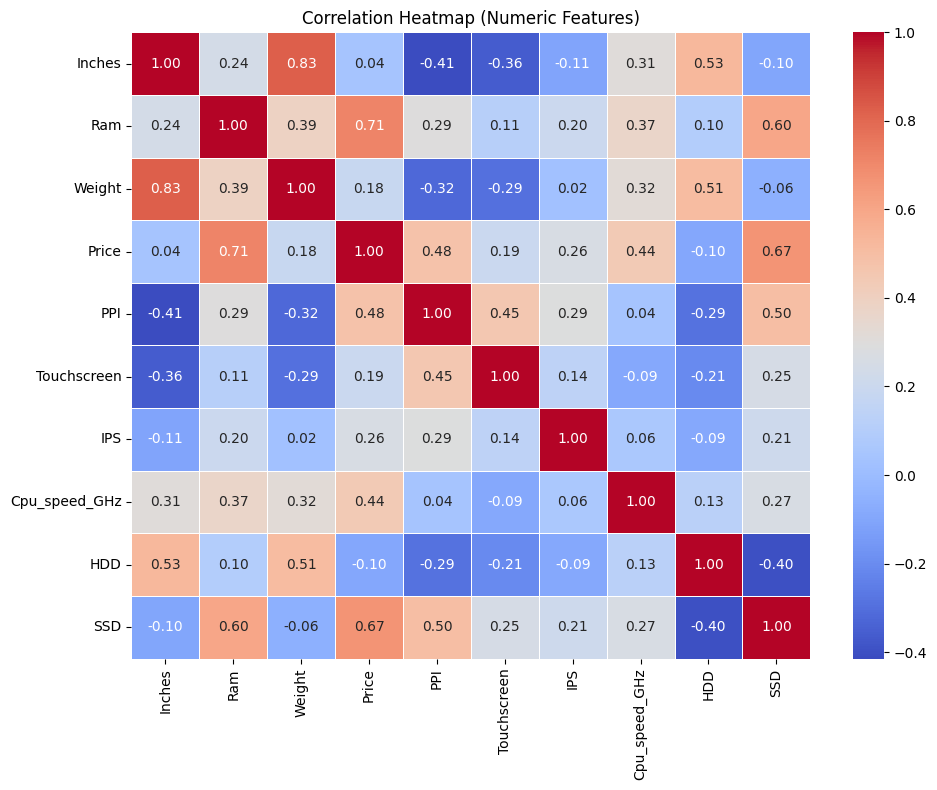

Categorical features: ['Company', 'TypeName', 'OpSys', 'Cpu_brand']
Numerical features: ['Inches', 'Ram', 'Weight', 'PPI', 'Touchscreen', 'IPS', 'Cpu_speed_GHz', 'HDD', 'SSD']


,Model,R2,MAE (TK),RMSE (TK)
1,Gradient Boosting,0.849636,20208.907444,27792.955076
2,Random Forest,0.834813,20291.128177,29130.740344
3,Lasso Regression,0.774936,26319.943021,34002.917155
4,Linear Regression,0.774755,26348.455979,34016.586042
5,Ridge Regression,0.765895,27558.205344,34679.112663
6,Decision Tree,0.733638,26452.082873,36991.251210


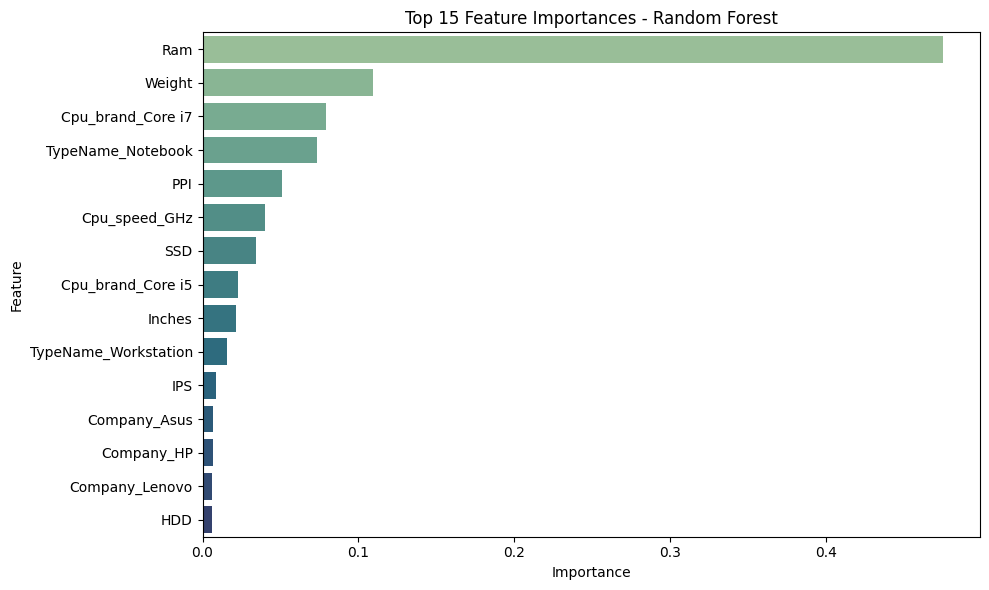

Execution completed successfully!


In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

# ==========================================
# 2. LOAD DATASET
# ==========================================
# Adjust file path if necessary based on your folder structure
df = pd.read_csv('laptop_price.csv', encoding='latin-1')

print(f"Initial Dataset Shape: {df.shape}")
display(df.head())

# ==========================================
# 3. DATA CLEANING & PREPROCESSING
# ==========================================
# Drop duplicate rows (excluding laptop_ID)
df = df.drop(columns=['laptop_ID'])
initial_len = len(df)
df = df.drop_duplicates()
print(f"Dropped {initial_len - len(df)} duplicate rows. New shape: {df.shape}")

# Check for missing values
print("Missing values per column:\n", df.isnull().sum())

# Clean 'Ram' and 'Weight' (strip suffixes and convert to numeric)
df['Ram'] = df['Ram'].str.replace('GB', '', regex=True).astype(int)
df['Weight'] = df['Weight'].str.replace('kg', '', regex=True).astype(float)

# Convert Price from Euros to BDT (TK) approximately to align with presentation metrics
# 1 Euro = ~115 BDT
EURO_TO_BDT = 115.0
df['Price'] = df['Price_euros'] * EURO_TO_BDT
df.drop(columns=['Price_euros'], inplace=True)

# Outlier Treatment on Price using IQR & Capping (Winsorization)
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Cap outliers instead of deleting
df['Price'] = df['Price'].clip(lower=lower_bound, upper=upper_bound)
print("Outlier treatment completed via IQR winsorization.")

# ==========================================
# 4. FEATURE ENGINEERING
# ==========================================
# Extract PPI (Pixels Per Inch) from ScreenResolution
df['X_res'] = df['ScreenResolution'].str.findall(r'(\d+)[xX](\d+)').apply(lambda x: int(x[0][0]) if len(x)>0 else 0)
df['Y_res'] = df['ScreenResolution'].str.findall(r'(\d+)[xX](\d+)').apply(lambda x: int(x[0][1]) if len(x)>0 else 0)
df['PPI'] = ((df['X_res']**2 + df['Y_res']**2)**0.5 / df['Inches']).astype(float)

# Extract Touchscreen and IPS panel flags
df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if 'Touchscreen' in x else 0)
df['IPS'] = df['ScreenResolution'].apply(lambda x: 1 if 'IPS' in x else 0)

# Extract CPU Brand & Speed
def fetch_processor(text):
    s = text.split()
    if s[0] == 'Intel':
        if len(s) > 1 and s[1] in ['Core']:
            if len(s) > 2:
                return s[1] + ' ' + s[2]
            return 'Intel Core'
        return 'Other Intel Processor'
    elif s[0] == 'AMD':
        return 'AMD Processor'
    else:
        return 'Other Processor'

df['Cpu_brand'] = df['Cpu'].apply(fetch_processor)
df['Cpu_speed_GHz'] = df['Cpu'].apply(lambda x: float(x.split()[-1].replace('GHz', '')) if 'GHz' in x else 0.0)

# Parse Memory (SSD and HDD capacities)
df['Memory'] = df['Memory'].astype(str).str.replace(r'\.0', '', regex=True)
df['Memory'] = df['Memory'].str.replace('GB', '')
df['Memory'] = df['Memory'].str.replace('TB', '000')
new = df['Memory'].str.split("+", n=1, expand=True)

df['first'] = new[0].str.strip()
df['Layer1HDD'] = df['first'].apply(lambda x: 1 if "HDD" in x else 0)
df['Layer1SSD'] = df['first'].apply(lambda x: 1 if "SSD" in x else 0)

import re
def extract_num(val):
    nums = re.findall(r'\d+', str(val))
    return int(nums[0]) if nums else 0

df['first'] = df['first'].apply(extract_num)
df['Second'] = new[1].fillna("0")
df['Layer2HDD'] = df['Second'].apply(lambda x: 1 if "HDD" in x else 0)
df['Layer2SSD'] = df['Second'].apply(lambda x: 1 if "SSD" in x else 0)
df['Second'] = df['Second'].apply(extract_num)

df['HDD'] = (df['first'] * df['Layer1HDD'] + df['Second'] * df['Layer2HDD'])
df['SSD'] = (df['first'] * df['Layer1SSD'] + df['Second'] * df['Layer2SSD'])

# Drop redundant raw columns
df.drop(columns=['first', 'Second', 'Layer1HDD', 'Layer1SSD',
                 'Layer2HDD', 'Layer2SSD', 'ScreenResolution', 'Cpu', 'Memory', 'X_res', 'Y_res', 'Product', 'Gpu'], inplace=True)

print("Feature engineering complete. Retained features:", df.columns.tolist())

# ==========================================
# 5. EXPLORATORY DATA ANALYSIS (EDA) & CORRELATION
# ==========================================
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

# ==========================================
# 6. MODEL DEVELOPMENT & TRAINING PIPELINE
# ==========================================
X = df.drop(columns=['Price'])
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Categorical features: {categorical_cols}")
print(f"Numerical features: {numerical_cols}")

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

# Define models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10),
    "Lasso Regression": Lasso(alpha=0.001),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({"Model": name, "R2": r2, "MAE (TK)": mae, "RMSE (TK)": rmse})

results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False).reset_index(drop=True)
results_df.index += 1
display(results_df)

# ==========================================
# 7. FEATURE IMPORTANCE (CHAMPION MODEL: RANDOM FOREST)
# ==========================================
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', models["Random Forest"])])
rf_pipeline.fit(X_train, y_train)

# Extract feature names after OneHotEncoding
cat_encoder = rf_pipeline.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(categorical_cols))
all_features = encoded_cat_cols + numerical_cols

importances = rf_pipeline.named_steps['model'].feature_importances_
feat_imp_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='crest')
plt.title("Top 15 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

print("Execution completed successfully!")